# Microrobot: transistor drivers and first bias layout

Companion to `microrobot.ipynb`. This notebook validates provenance and renders **previously executed** SPICE/Magic/Netgen results. It does not claim those tools ran inside this notebook's default execution. Set `REGENERATE=True` to repeat external simulations and physical checks in fresh directories.

**Scope:** finite actuator PV + transistor drivers + reduced electrochemical loads; separately, a routed bias macro embedded in a schematic clock/first DFF. Phase, ready and logic supply are ideal driver-bench stimuli. Brownout remains a rejected candidate. There is no assembled controller or fabrication signoff.

See [physical validation](PHYSICAL_VALIDATION.md) for units, exact tool versions, corner coverage, failed iterations and attribution. Python dependencies are pinned in `requirements-lock.txt`.

In [1]:
from pathlib import Path
import hashlib, json, os, sys
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display

ROOT = Path.cwd()
while not (ROOT / 'opentcad').is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
assert (ROOT / 'opentcad').is_dir(), 'Run inside the OpenTCAD repository'
sys.path.insert(0, str(ROOT))
APP = ROOT / 'examples/microrobot'
RESULTS = APP / 'results'
manifest = json.loads((RESULTS / 'milestone3_manifest.json').read_text())
for relative, expected in manifest['sha256'].items():
    assert hashlib.sha256((APP / relative).read_bytes()).hexdigest() == expected, relative
print(f"Verified {len(manifest['sha256'])} archived source/artifact checksums")
REGENERATE = False
EDIR = RESULTS / 'electrical_v2'
LDIR = RESULTS / 'layout/bias_reference_final'
if REGENERATE:
    import uuid
    from examples.microrobot.electrical import run as run_electrical
    from examples.microrobot.layout import run as run_layout
    fresh = APP / 'local_runs' / ('notebook_m3_' + uuid.uuid4().hex[:8])
    EDIR, LDIR = fresh / 'electrical', fresh / 'layout'
    run_electrical(EDIR)
    run_layout(LDIR)  # requires Magic, NETGEN and installed SKY130A
else:
    print('Archive-review mode: external tools were run separately, not rerun here.')
electrical = json.loads((EDIR / 'summary.json').read_text())
layout = json.loads((LDIR / 'summary.json').read_text())
storage = layout['storage_iteration']
tolerance = layout['tolerance_audit']

Verified 326 archived source/artifact checksums
Archive-review mode: external tools were run separately, not rerun here.


## Drivers and electrode interfaces

Five process corners plus hot, half-light, slow-input and half-timestep checks pass the stated preliminary output criteria. Phase is 3 Hz with quarter-cycle separation. The shaded interval forces ready low and removes the ideal logic supply. Electrode voltage relative to Pt metal and local electrode/solution potential are different quantities.

The interface has double-layer charging, finite adsorption kinetics and Faradaic leakage. Its chosen parameters are not calibrated to measured bending or electrochemical durability. Analytical tests check independent RC, adsorption and charge limits.

TT actuator PV delivery: 2.3946 nW
Energy per 3 Hz cycle (two outputs): 0.7982 nJ
Timestep relative changes: {'actuator_PV_mean_W': 0.00025563383956750396, 'phase_A_eta_peak_to_peak_V': 1.881527875724487e-07}
Few-pW logic/stimulus residual powers are not numerically converged estimates.


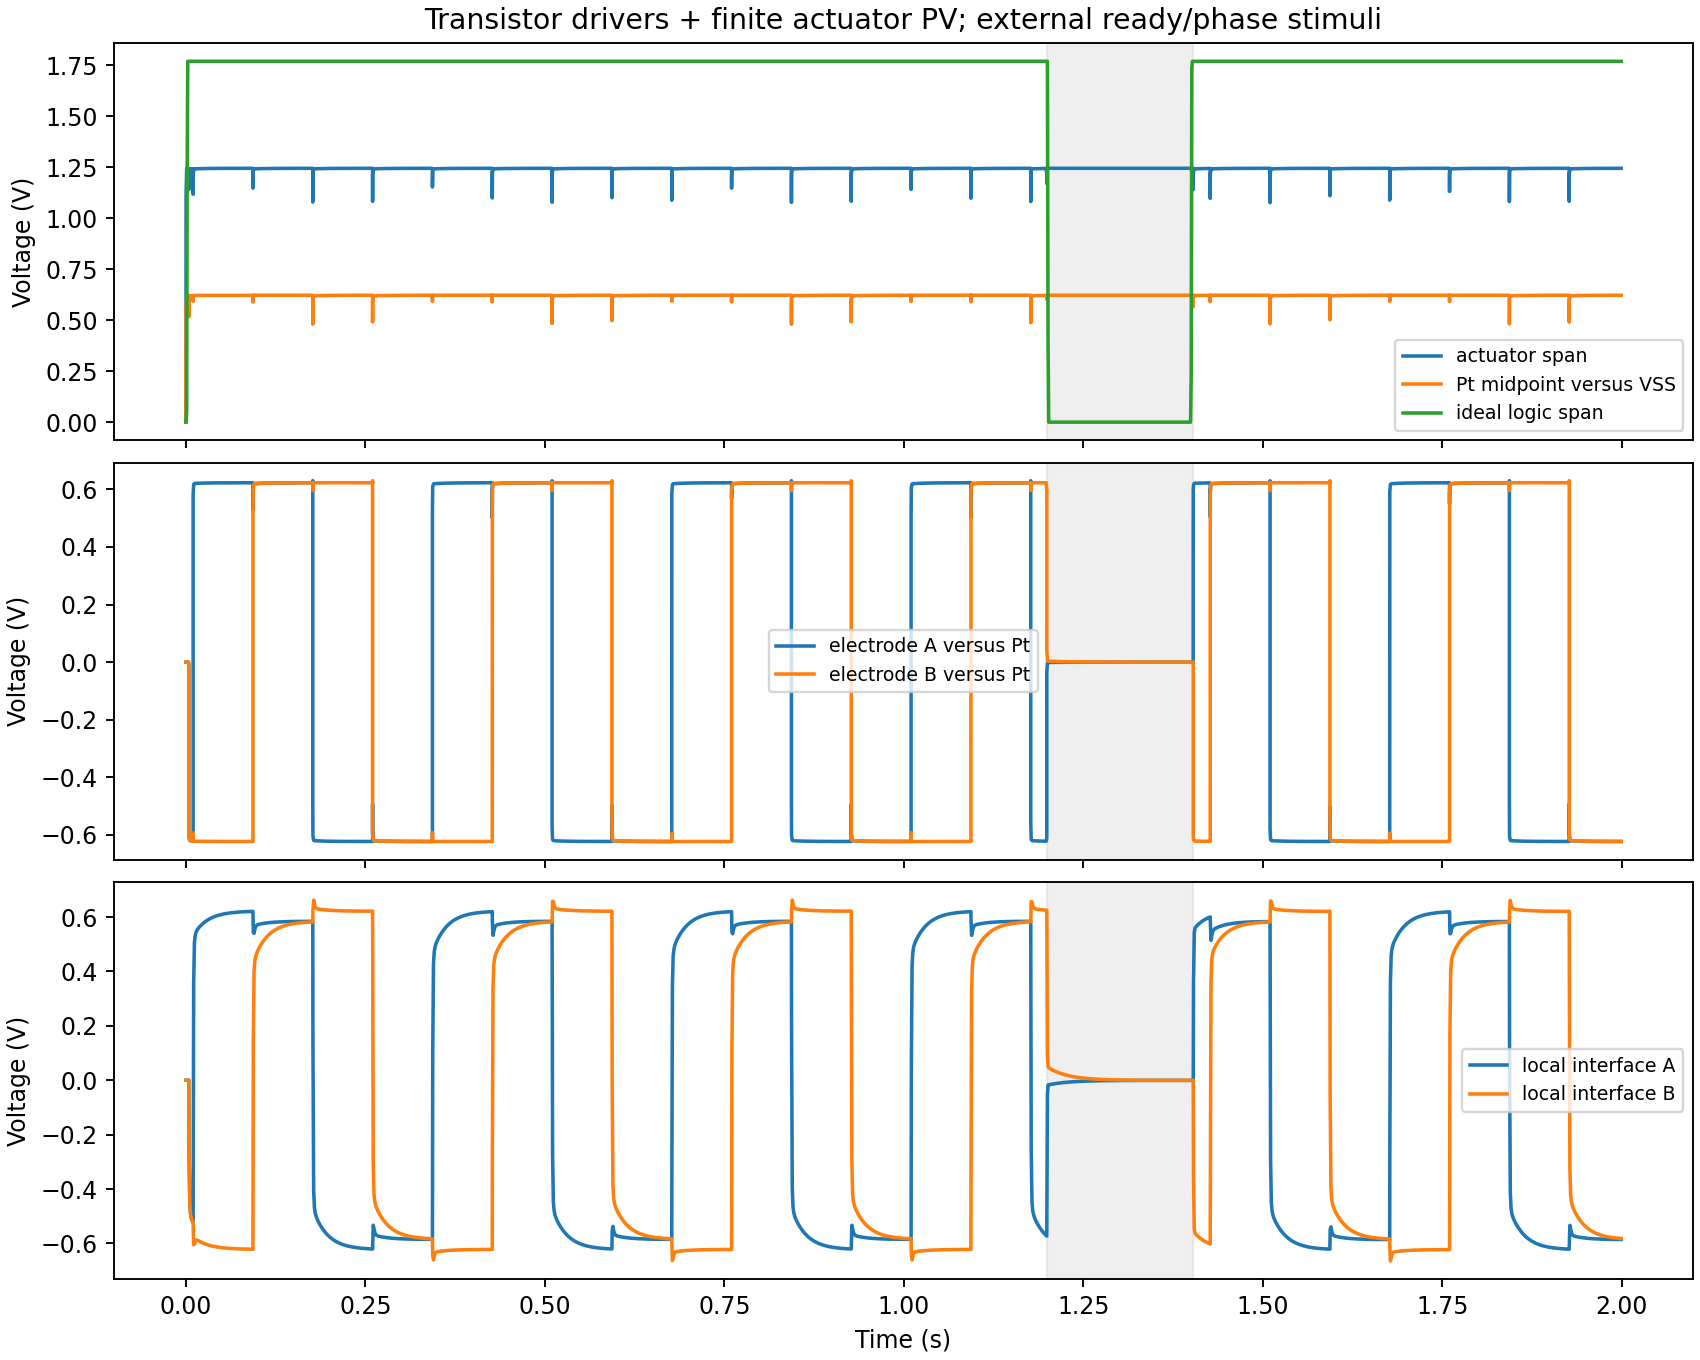

In [2]:
drivers = electrical['drivers'] + [electrical[k] for k in
    ('driver_timestep_half', 'driver_slow_inputs', 'driver_hot', 'driver_half_light')]
assert len(drivers) == 9 and all(d['passed'] for d in drivers)
nominal = drivers[0]
print(f"TT actuator PV delivery: {nominal['actuator_PV_mean_W']*1e9:.4f} nW")
print(f"Energy per 3 Hz cycle (two outputs): {nominal['actuator_PV_mean_W']/3*1e9:.4f} nJ")
print('Timestep relative changes:', electrical['driver_timestep_relative_changes'])
print('Few-pW logic/stimulus residual powers are not numerically converged estimates.')
display(Image(filename=str(EDIR / 'drivers.png')))

## Rejected brownout candidate

The comparator has hysteresis in a slow transient supply ramp. FS turn-on is above the previously simulated FS PV-powered clock rail; autonomous enable fails. The 85 °C case also has substantial power and threshold drift. This circuit has not been accepted or laid out. The standalone driver tests use an external ready signal.

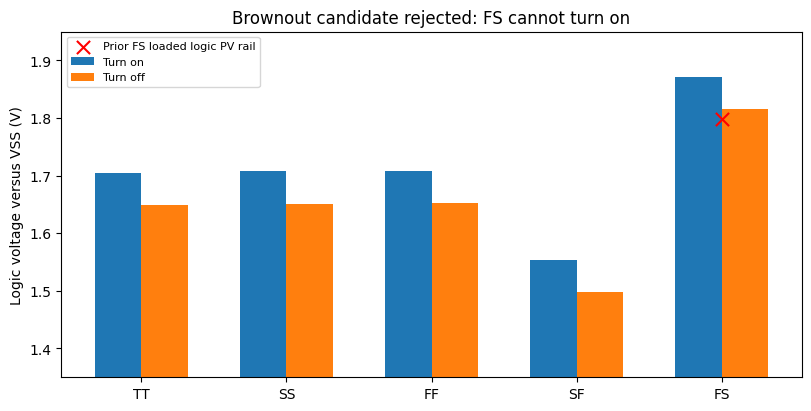

In [3]:
corners = electrical['brownout'][:5]
x = np.arange(len(corners))
fig, ax = plt.subplots(figsize=(8, 4), layout='constrained')
ax.bar(x-.16, [c['turn_on_V'] for c in corners], width=.32, label='Turn on')
ax.bar(x+.16, [c['turn_off_V'] for c in corners], width=.32, label='Turn off')
ax.scatter([4], [1.79847], color='red', marker='x', s=90, label='Prior FS loaded logic PV rail')
ax.set(xticks=x, xticklabels=[c['corner'].upper() for c in corners],
       ylabel='Logic voltage versus VSS (V)', ylim=(1.35,1.95),
       title='Brownout candidate rejected: FS cannot turn on')
ax.legend(fontsize=8)
fig.savefig(EDIR / 'brownout.png', dpi=170)
plt.show()

## Routed bias macro

This layout contains five MOS devices and two MIM capacitors. Equal NMOS orientation, adjacent sensing/mirror devices, PDK guard structures and well/substrate contacts are included. It is a spacious prototype, not footprint optimized or statistically matched.

The native layout and exported/reimported GDS pass PDK DRC and LVS. A deliberately wrong gate connection fails LVS. Rectangular port markers preserve pin interfaces through GDS. Only this bias macro is extracted; the remaining clock/first DFF and storage remain schematic.

Dimensions (µm): {'width_um': 92.4, 'height_um': 40.265}
RC parasitics: 152 resistors, 45 capacitors
Physical checks cover this bias macro only.


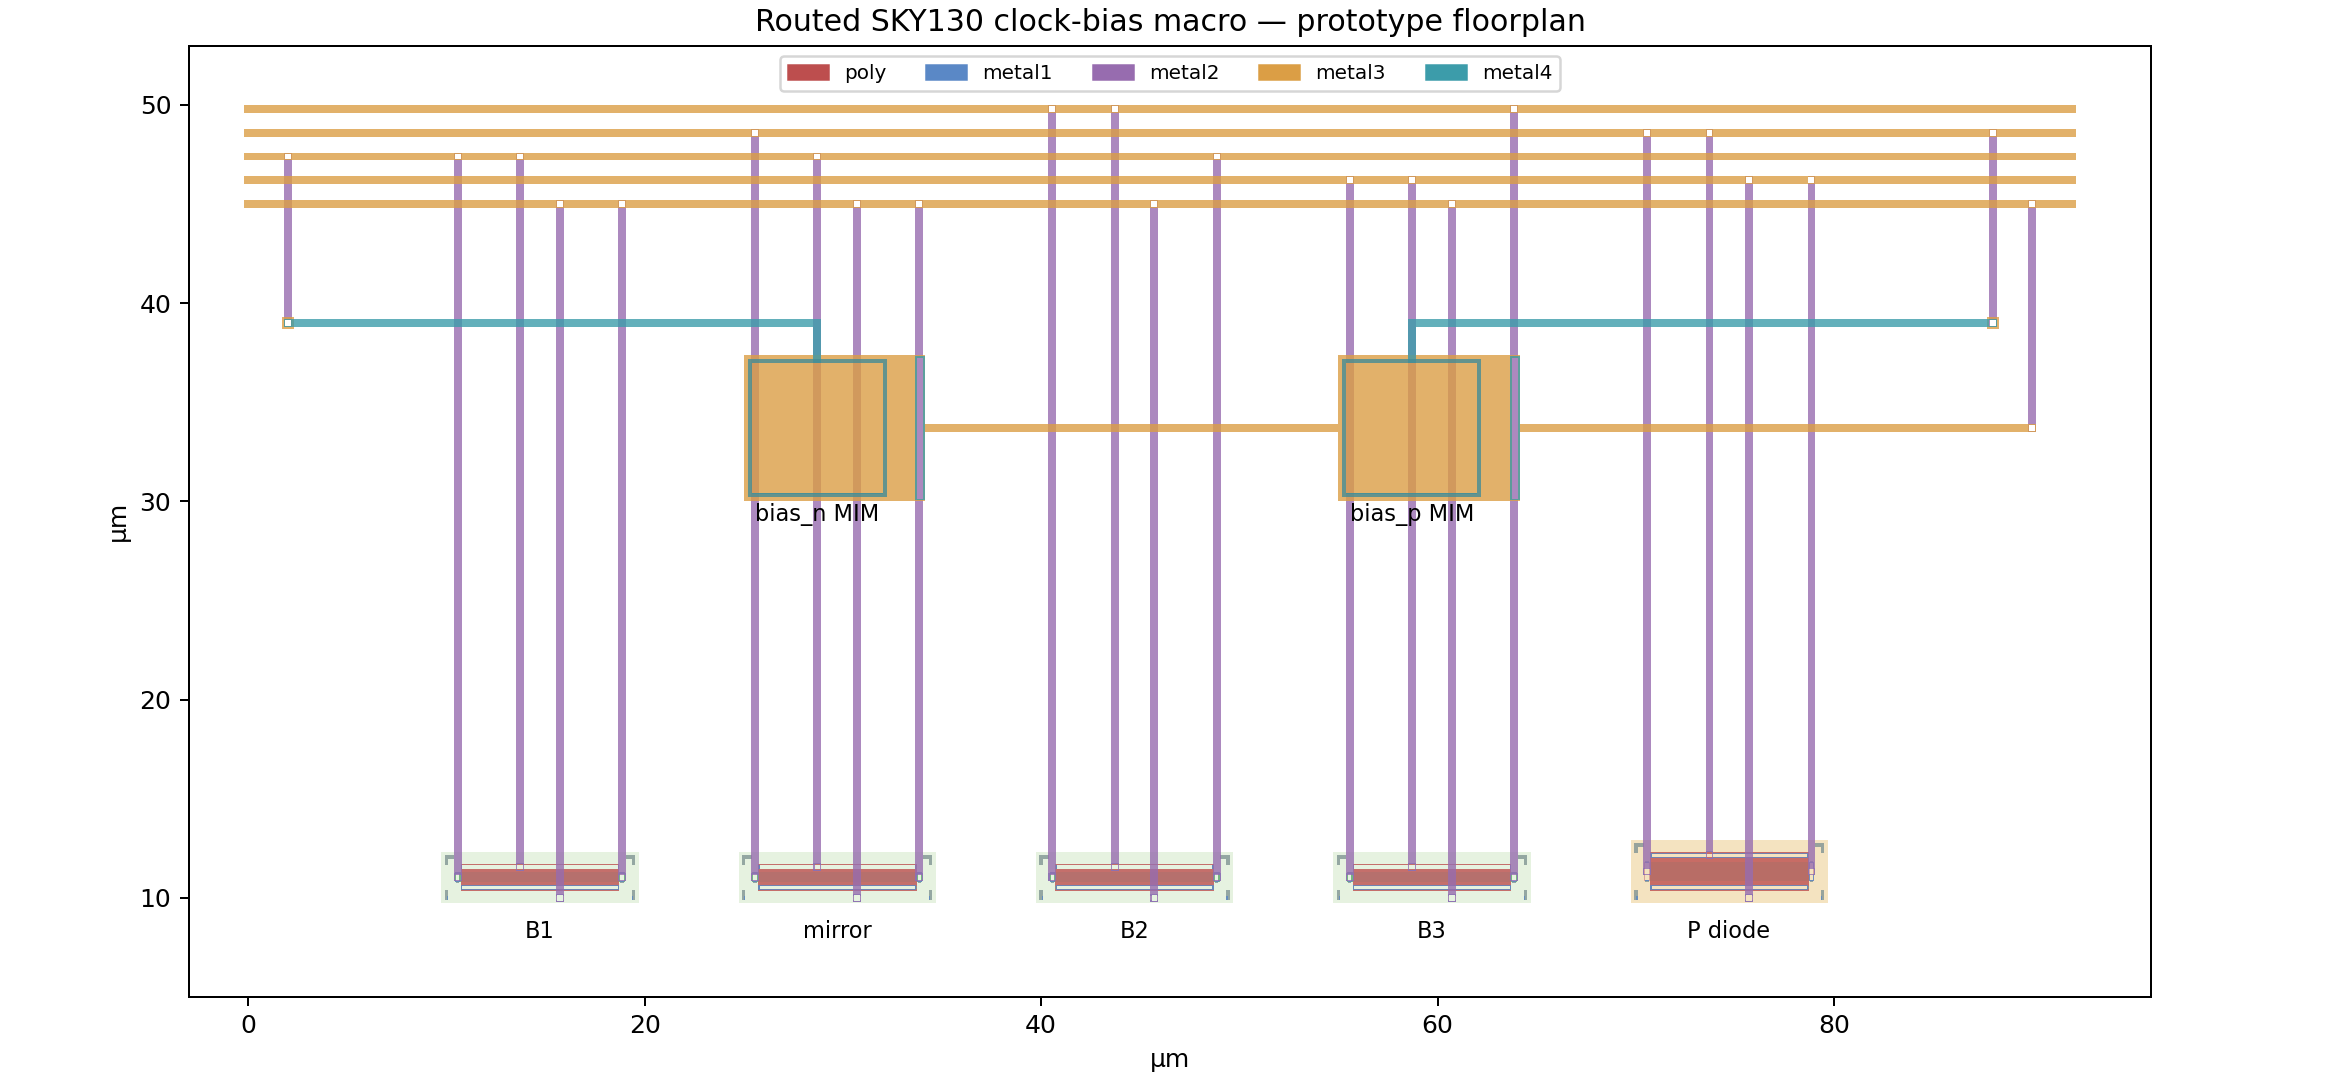

In [4]:
assert layout['drc_errors'] == 0 and layout['lvs_match']
assert layout['intentional_wrong_gate_rejected']
assert layout['gds_roundtrip'] == {'drc_errors': 0, 'lvs_match': True}
print('Dimensions (µm):', layout['dimensions'])
print('RC parasitics:', layout['rc_resistors'], 'resistors,', layout['rc_capacitors'], 'capacitors')
print('Physical checks cover this bias macro only.')
display(Image(filename=str(LDIR / 'layout.png')))

## Extraction exposed a supply-storage problem

Loose-tolerance simulations produced inconsistent failures across storage choices and fresh extraction. A passing 3 pF run did not reproduce; increasing storage was not an established fix. Tightening ngspice `reltol` from 1e-4 to 1e-6 makes the original 2 pF design pass at 50 ns and 25 ns, with individual divider edges checked. This is consistent with a numerical artifact at loose settings. The nominal design retains 2 pF.

The matched comparison holds storage, timestep and tolerance fixed (2 pF, 25 ns, 1e-6). It covers a 4 ms TT experiment with only the bias macro extracted. Full PVT and controller integration remain pending. The right panel retains the coarse 5 pF failure alongside its tight-tolerance result.

Matched 2 pF relative changes: {'frequency_Hz': -0.009148240628422455, 'mean_power_W': 0.001999854071349283, 'first_high_crossing_s': 0.12229650722608465}
2 pF timestep changes: {'frequency_Hz': 4.451874543254242e-05, 'mean_power_W': 8.695000617064963e-06}


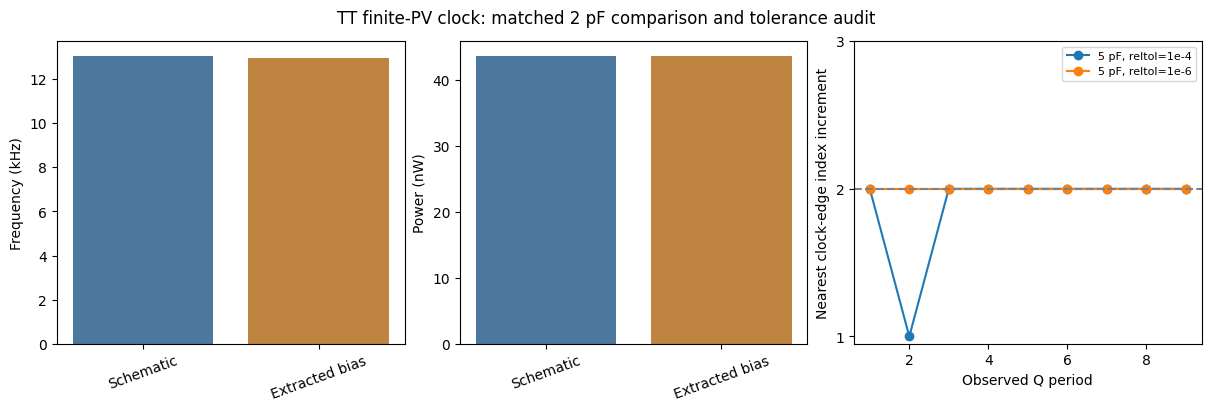

In [5]:
assert not storage['accepted_nominal_3pf'] and not storage['accepted_nominal_5pf']
assert tolerance['nominal_2pf_qualified'] and tolerance['nominal_5pf_qualified']
pre, post = tolerance['pre_pv_2pf_tight_halfstep'], tolerance['post_pv_2pf_tight_halfstep']
print('Matched 2 pF relative changes:', tolerance['matched_2pf_relative_changes'])
print('2 pF timestep changes:', tolerance['2pf_timestep_relative_changes'])
fig, axes = plt.subplots(1, 3, figsize=(12, 4), layout='constrained')
for ax, key, scale, unit in zip(axes[:2], ['frequency_Hz','mean_power_W'],
                              [1e-3,1e9], ['Frequency (kHz)','Power (nW)']):
    ax.bar(['Schematic','Extracted bias'], [pre[key]*scale,post[key]*scale], color=['#4c789f','#bf8540'])
    ax.set(ylabel=unit)
    ax.tick_params(axis='x',labelrotation=20)
for result, label in [(storage['post_pv_5pf'],'5 pF, reltol=1e-4'),
                      (tolerance['post_pv_5pf_tight'],'5 pF, reltol=1e-6')]:
    counts=result['clock_edges_per_divided_period']
    axes[2].plot(np.arange(1,len(counts)+1), counts, 'o-', label=label)
axes[2].axhline(2,color='grey',linestyle='--')
axes[2].set(xlabel='Observed Q period',ylabel='Nearest clock-edge index increment',yticks=[1,2,3])
axes[2].legend(fontsize=8)
fig.suptitle('TT finite-PV clock: matched 2 pF comparison and tolerance audit')
fig.savefig(LDIR / 'postlayout.png', dpi=170)
plt.show()

## Validation and remaining work

The full regression suite passed **174 tests** with one pre-existing Auger diagnostic warning. Two new SPICE tests validate electrode analytical limits/charge conservation; two divider-audit tests verify that threshold alignment is tolerated and missed events are rejected. A fresh layout-generator run also passed physical verification.

The earlier end-to-end notebook retains its original 2 pF supply and reduced driver/mechanics model. These separate transistor experiments do not retroactively validate that complete chain. Next steps are brownout/reference redesign, tight-tolerance clock qualification across corners, coupled supply/reset integration, oscillator and driver layout, digital macro assembly, and complete pre/post-layout electrical validation. No contest submission or fabrication has been performed. Repository delivery is recorded separately in Git history.

Original contributions and underlying tool attribution are described in [PHYSICAL_VALIDATION.md](PHYSICAL_VALIDATION.md); paper evidence and extraction provenance are in [references.md](references.md).